# Serial Hybrid Model - ML (Udata) -> Physics (Taout, Twout)

**Approach:** ML and physics run in series.

1. **Physics / data prep (section 2)**
   - Fixed **TEMA Type A** shell, 2-pass tubes (triangular pitch)
   - Compute **`Udata`** for every row with the **LMTD** method from dataset temperatures
2. **ML branch (section 3):** predict `U` from `(m_air, m_water, T_air_in, T_water_in)` using target **`Udata`**
3. **Serial hybrid:** ML `U` -> physics E-NTU -> `Taout`, `Twout`

**Inputs:** air/water mass flow, air/water inlet temperature  
**Outputs:** Overall U (ML), air outlet temp, water outlet temp


## 1. Libraries and data


In [55]:
# LIBRARIES AND DATA LOADING
# Serial hybrid pipeline:
#   1) Load data.csv temperatures & flows
#   2) Compute Udata (LMTD) in section 2
#   3) ML predicts U from Udata
#   4) Physics E-NTU uses ML U for Taout, Twout

import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# Use data.csv from this notebook folder (Serial Model)
DATA_DIR = Path(r"c:\Users\krish\JBS Tech\Heat exchanger Digital Twin\Serial Model")
data_path = DATA_DIR / "data.csv"
if not data_path.exists():
    data_path = Path("data.csv")
if not data_path.exists():
    raise FileNotFoundError("data.csv not found in Serial Model folder")

df_raw = pd.read_csv(data_path, header=1)

if "State" in df_raw.columns:
    df_raw = df_raw[df_raw["State"].astype(str).str.startswith("Case")].copy()

cols = {
    "Hot Air flow in Shell": "m_air_kgh",
    "Cooling water flow in Tubes": "m_water_kgh",
    "1 - Temperature": "T_air_in",
    "3 - Temperature": "T_water_in",
    "2 - Temperature": "T_air_out",
    "4 - Temperature": "T_water_out",
    "E-100 - Overall U": "U_actual",
}

df = df_raw[list(cols.keys())].rename(columns=cols).copy()

for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna().reset_index(drop=True)

# kg/h -> kg/s for physics
df["m_air"] = df["m_air_kgh"] / 3600.0
df["m_water"] = df["m_water_kgh"] / 3600.0

print("Loaded dataset:", data_path.resolve())
print("Shape:", df.shape)
print(df.head())


Loaded dataset: C:\Users\krish\JBS Tech\Models\Heat exchanger Digital Twin\Serial Model\data.csv
Shape: (7526, 9)
   m_air_kgh  m_water_kgh  T_air_in  T_water_in  T_air_out  T_water_out  \
0    10000.0      10000.0     100.0        25.0      69.25        32.12   
1    10000.0      10000.0     150.0        25.0      98.14        37.10   
2    10000.0      10000.0     200.0        25.0     126.70        42.24   
3    10000.0      10000.0     250.0        25.0     155.00        47.50   
4    10000.0      10000.0     300.0        25.0     183.10        52.89   

   U_actual     m_air   m_water  
0     26.67  2.777778  2.777778  
1     27.33  2.777778  2.777778  
2     27.94  2.777778  2.777778  
3     28.49  2.777778  2.777778  
4     28.98  2.777778  2.777778  


## 2. Physics model (TEMA Type A, 2-pass tubes)

Temperature-dependent properties + iterative E-NTU rating.

- Operating inputs `T_air_in`, `m_dot_air`, `T_water_in`, `m_dot_water` come from **each dataset row**.
- Fixed geometry: TEMA Type A shell, 2-pass tubes (triangular pitch).
- **Udata**: overall U calculated from dataset temperatures using **LMTD** method (saved as `df["Udata"]`).
- For the **serial hybrid**, `physics_outlets_from_U` takes **ML `U`** and calculates outlets only.


In [56]:
# PHYSICS MODEL — TEMA Type A shell, 2-pass tubes
# Operating inputs (T_air_in, m_dot_air, T_water_in, m_dot_water)
# must be supplied from each dataset row.

# ----- Inlet pressures (absolute, Pa) -----
# data.csv has no pressure columns, so these fixed values are used for every row.
ATM = 101325.0                 # 1 atm in Pa
P_AIR_IN = 1.5 * ATM           # Air inlet pressure (shell side)
P_WATER_IN = 2.0 * ATM         # Water inlet pressure (tube side)


def get_water_saturation_temp(P):
    """Boiling (saturation) temperature of water (°C) at pressure P (Pa).
    Antoine equation, two ranges: 1–100 °C and 99–374 °C."""
    P_mmHg = P / 133.322
    if P_mmHg >= 760.0:
        A, B, C = 8.14019, 1810.94, 244.485
    else:
        A, B, C = 8.07131, 1730.63, 233.426
    return B / (A - math.log10(P_mmHg)) - C


def get_water_properties(T_c, P=P_WATER_IN):
    """Water properties at temperature T_c (°C) and pressure P (Pa)."""
    # Liquid range: 1 °C up to the boiling point at P
    T = max(1.0, min(T_c, get_water_saturation_temp(P)))
    # Small compression correction (bulk modulus ~2.2 GPa)
    rho = (1000.0 - 0.0178 * abs(T - 4.0) ** 1.7) * (1.0 + (P - ATM) / 2.2e9)
    mu = 0.00179 * math.exp(-0.0247 * T)
    cp = 4182.0 - 0.25 * T
    k = 0.57 + 0.0017 * T
    Pr = (cp * mu) / k
    return rho, mu, cp, k, Pr


def get_air_properties(T_c, P=P_AIR_IN):
    """Air properties at temperature T_c (°C) and pressure P (Pa)."""
    T_k = T_c + 273.15
    R_spec = 287.05
    rho = P / (R_spec * T_k)

    mu_ref = 1.716e-5
    T_ref = 273.15
    S = 110.4
    mu = mu_ref * ((T_k / T_ref) ** 1.5) * ((T_ref + S) / (T_k + S))

    cp = 1005.0 + 0.05 * T_c
    k = 0.0241 + 7.5e-5 * T_c
    Pr = (cp * mu) / k
    return rho, mu, cp, k, Pr


# ----- Fixed Geometry (TEMA Type A Shell, 2-Pass Tube) -----
N_TUBES = 160
N_PASSES = 2
L_TUBE = 6.0                 # m
D_O = 0.020                  # outer diameter (m)
WALL_THICKNESS = 0.002       # m
PITCH = 0.050                # triangular pitch (m)
D_S = 0.387                  # shell diameter (m)
B_BAFFLE = 0.8               # baffle spacing (m)
K_WALL = 45.0                # W/m·K
R_FI = 0.00015               # fouling inside (m²·K/W)
R_FO = 0.00035               # fouling outside (m²·K/W)

D_I = D_O - 2.0 * WALL_THICKNESS
A_O_TOTAL = N_TUBES * (math.pi * D_O * L_TUBE)
N_TUBES_PER_PASS = N_TUBES / N_PASSES
A_FLOW_TUBE = N_TUBES_PER_PASS * (math.pi * D_I ** 2 / 4)
C_PRIME = PITCH - D_O
A_S = (D_S * C_PRIME * B_BAFFLE) / PITCH
# Equivalent diameter for triangular pitch (Kern)
D_E = 4.0 * (0.86 * PITCH ** 2 - (math.pi * D_O ** 2 / 4.0)) / (math.pi * D_O)

# Alias used by physics_outlets_from_U
A_o_total = A_O_TOTAL
print(f"Fixed geometry A_o = {A_o_total:.4f} m²  (TEMA A, triangular pitch)")


def rate_shell_and_tube_1_2(
    T_air_in,
    m_dot_air,
    T_water_in,
    m_dot_water,
    P_air_in=P_AIR_IN,
    P_water_in=P_WATER_IN,
    tol=1e-5,
    max_iter=100,
    omega=0.5,
):
    """
    Physics rating for one operating point from the dataset.
    Required inputs (from each data row):
      T_air_in, m_dot_air, T_water_in, m_dot_water
    Optional: inlet pressures P_air_in, P_water_in (Pa, absolute).
    Fixed TEMA Type A / 2-pass geometry is used inside.
    """
    d_i = D_I
    d_o = D_O
    A_o = A_O_TOTAL
    A_flow_tube = A_FLOW_TUBE
    A_s = A_S
    D_e = D_E

    T_h_out = T_air_in - 30.0
    T_c_out = T_water_in + 10.0

    for iteration in range(1, max_iter + 1):
        T_h_avg = 0.5 * (T_air_in + T_h_out)
        T_c_avg = 0.5 * (T_water_in + T_c_out)

        rho_w, mu_w, cp_w, k_w, Pr_w = get_water_properties(T_c_avg, P_water_in)
        rho_a, mu_a, cp_a, k_a, Pr_a = get_air_properties(T_h_avg, P_air_in)

        # Tube-side (water) — Dittus–Boelter
        u_i = m_dot_water / (rho_w * A_flow_tube)
        Re_i = (rho_w * u_i * d_i) / mu_w
        Nu_i = 0.023 * (Re_i ** 0.8) * (Pr_w ** 0.4)
        h_i = (Nu_i * k_w) / d_i

        # Shell-side (air) — Kern
        G_s = m_dot_air / A_s
        Re_s = (G_s * D_e) / mu_a
        Nu_o = 0.36 * (Re_s ** 0.55) * (Pr_a ** (1.0 / 3.0))
        h_o = (Nu_o * k_a) / D_e

        # Overall U (outer area)
        R_conv_i = (1.0 / h_i) * (d_o / d_i)
        R_foul_i = R_FI * (d_o / d_i)
        R_cond = (d_o * math.log(d_o / d_i)) / (2.0 * K_WALL)
        U_o = 1.0 / (R_conv_i + R_foul_i + R_cond + R_FO + 1.0 / h_o)

        # E-NTU (1 shell / 2 tube passes)
        C_h = m_dot_air * cp_a
        C_c = m_dot_water * cp_w
        C_min = min(C_h, C_c)
        C_max = max(C_h, C_c)
        C_r = C_min / C_max

        NTU = (U_o * A_o) / C_min
        E = math.sqrt(1.0 + C_r ** 2)
        exp_term = math.exp(-NTU * E)
        epsilon = 2.0 / (1.0 + C_r + E * ((1.0 + exp_term) / (1.0 - exp_term)))

        Q = epsilon * C_min * (T_air_in - T_water_in)
        T_h_out_new = T_air_in - (Q / C_h)
        T_c_out_new = T_water_in + (Q / C_c)

        diff = max(abs(T_h_out_new - T_h_out), abs(T_c_out_new - T_c_out))
        if diff < tol:
            T_h_out, T_c_out = T_h_out_new, T_c_out_new
            break

        T_h_out = omega * T_h_out_new + (1.0 - omega) * T_h_out
        T_c_out = omega * T_c_out_new + (1.0 - omega) * T_c_out

    return {
        "Iterations_to_Converge": iteration,
        "U_phys": float(U_o),
        "T_air_out_phys": float(T_h_out),
        "T_water_out_phys": float(T_c_out),
        "P_air_in_kPa": float(P_air_in / 1000.0),
        "P_water_in_kPa": float(P_water_in / 1000.0),
        "Q_kW": float(Q / 1000.0),
        "NTU": float(NTU),
        "epsilon": float(epsilon),
        "A_o_total": float(A_o),
    }


# Demo: take operating inputs from the first dataset row
_row0 = df.iloc[0]
demo = rate_shell_and_tube_1_2(
    T_air_in=float(_row0["T_air_in"]),
    m_dot_air=float(_row0["m_air"]),
    T_water_in=float(_row0["T_water_in"]),
    m_dot_water=float(_row0["m_water"]),
)
print("Demo using dataset row 0:")
for k, v in demo.items():
    print(f"  {k}: {v}")


Fixed geometry A_o = 60.3186 m²  (TEMA A, triangular pitch)
Demo using dataset row 0:
  Iterations_to_Converge: 21
  U_phys: 39.228343360852435
  T_air_out_phys: 60.083113964461724
  T_water_out_phys: 34.64805282282843
  P_air_in_kPa: 151.9875
  P_water_in_kPa: 202.65
  Q_kW: 111.87839155123004
  NTU: 0.8442314162900545
  epsilon: 0.5322251471405103
  A_o_total: 60.318578948924035


In [57]:
# PHYSICS OUTLETS FROM A GIVEN U (used by serial hybrid)
# U comes from ML — this function does NOT calculate U from hi/ho.
# Same E-NTU (1-2 pass) + fluid properties + fixed TEMA area.


def physics_outlets_from_U(
    U_o,
    T_air_in,
    T_water_in,
    m_dot_air,
    m_dot_water,
    P_air_in=P_AIR_IN,
    P_water_in=P_WATER_IN,
    A_o=None,
    tol=1e-5,
    max_iter=100,
    omega=0.5,
):
    """Calculate Taout and Twout using E-NTU with a supplied overall U."""
    if A_o is None:
        A_o = A_o_total

    T_h_out = T_air_in - 30.0
    T_c_out = T_water_in + 10.0

    for iteration in range(1, max_iter + 1):
        T_h_avg = 0.5 * (T_air_in + T_h_out)
        T_c_avg = 0.5 * (T_water_in + T_c_out)

        _, _, cp_w, _, _ = get_water_properties(T_c_avg, P_water_in)
        _, _, cp_a, _, _ = get_air_properties(T_h_avg, P_air_in)

        C_h = m_dot_air * cp_a
        C_c = m_dot_water * cp_w
        C_min = min(C_h, C_c)
        C_max = max(C_h, C_c)
        C_r = C_min / C_max

        NTU = (U_o * A_o) / C_min
        E = math.sqrt(1.0 + C_r ** 2)
        exp_term = math.exp(-NTU * E)
        denom = 1.0 - exp_term
        if abs(denom) < 1e-15:
            epsilon = 1.0
        else:
            epsilon = 2.0 / (1.0 + C_r + E * ((1.0 + exp_term) / denom))

        Q = epsilon * C_min * (T_air_in - T_water_in)

        T_h_out_new = T_air_in - (Q / C_h)
        T_c_out_new = T_water_in + (Q / C_c)

        diff = max(abs(T_h_out_new - T_h_out), abs(T_c_out_new - T_c_out))
        if diff < tol:
            T_h_out, T_c_out = T_h_out_new, T_c_out_new
            break

        T_h_out = omega * T_h_out_new + (1.0 - omega) * T_h_out
        T_c_out = omega * T_c_out_new + (1.0 - omega) * T_c_out

    return {
        "T_air_out": float(T_h_out),
        "T_water_out": float(T_c_out),
        "Q_kW": float(Q / 1000.0),
        "NTU": float(NTU),
        "epsilon": float(epsilon),
        "iterations": iteration,
    }


# Demo: outlets using dataset row 0 operating inputs + a sample U
_row0 = df.iloc[0]
_demo = physics_outlets_from_U(
    U_o=50.0,
    T_air_in=float(_row0["T_air_in"]),
    T_water_in=float(_row0["T_water_in"]),
    m_dot_air=float(_row0["m_air"]),
    m_dot_water=float(_row0["m_water"]),
)
print("Demo outlets (dataset row 0, U=50):", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in _demo.items()})


Demo outlets (dataset row 0, U=50): {'T_air_out': 54.354, 'T_water_out': 36.032, 'Q_kW': 127.918, 'NTU': 1.076, 'epsilon': 0.609, 'iterations': 22}


In [58]:
# CALCULATE Udata FROM DATASET USING LMTD
# For each row:
#   LMTD = ((Tain-Twout) - (Taout-Twin)) / ln((Tain-Twout)/(Taout-Twin))
#   Thavg, Tcavg -> Cp_air, Cp_water
#   Qh = ma * Cp_h * (Tain - Taout)   # heat released by hot air
#   Qc = mw * Cp_c * (Twout - Twin)   # heat absorbed by cold water
#   Qavg = (Qh + Qc) / 2
#   Udata = Qavg / (A * LMTD)


def lmtd_counterflow(T_air_in, T_water_in, T_air_out, T_water_out, eps=1e-8):
    """LMTD = (dT1 - dT2) / ln(dT1/dT2), dT1=Tain-Twout, dT2=Taout-Twin."""
    dT1 = T_air_in - T_water_out
    dT2 = T_air_out - T_water_in
    if dT1 <= eps or dT2 <= eps:
        return float("nan")
    if abs(dT1 - dT2) < eps:
        return 0.5 * (dT1 + dT2)
    return (dT1 - dT2) / math.log(dT1 / dT2)


def udata_from_lmtd(m_air, m_water, T_air_in, T_water_in, T_air_out, T_water_out, A=None):
    """Compute overall U from measured/dataset temperatures via LMTD."""
    if A is None:
        A = A_o_total

    LMTD = lmtd_counterflow(T_air_in, T_water_in, T_air_out, T_water_out)
    if not math.isfinite(LMTD) or LMTD <= 0.0 or A <= 0.0:
        return float("nan")

    Thavg = 0.5 * (T_air_out + T_air_in)
    Tcavg = 0.5 * (T_water_in + T_water_out)

    _, _, Cp_h, _, _ = get_air_properties(Thavg)
    _, _, Cp_c, _, _ = get_water_properties(Tcavg)

    # Hot-side duty uses (Tain - Taout) so Qh > 0 when air cools
    # (equivalent magnitude to ma*Cp*(Taout-Tain) with opposite sign)
    Qh = m_air * Cp_h * (T_air_in - T_air_out)
    Qc = m_water * Cp_c * (T_water_out - T_water_in)
    Qavg = 0.5 * (Qh + Qc)

    return Qavg / (A * LMTD)


Udata_list = []
for _, row in df.iterrows():
    Udata_list.append(
        udata_from_lmtd(
            m_air=float(row["m_air"]),
            m_water=float(row["m_water"]),
            T_air_in=float(row["T_air_in"]),
            T_water_in=float(row["T_water_in"]),
            T_air_out=float(row["T_air_out"]),
            T_water_out=float(row["T_water_out"]),
            A=A_o_total,
        )
    )

df["Udata"] = Udata_list

print("Udata calculated for", len(df), "rows")
print("A used =", round(A_o_total, 4), "m²")
print(df[["T_air_in", "T_air_out", "T_water_in", "T_water_out", "U_actual", "Udata"]].head(8).to_string(index=False))
print("\nUdata stats:")
print(df["Udata"].describe().round(3))


Udata calculated for 7526 rows
A used = 60.3186 m²
 T_air_in  T_air_out  T_water_in  T_water_out  U_actual     Udata
    100.0      69.25        25.0        32.12     26.67 25.333225
    150.0      98.14        25.0        37.10     27.33 25.882739
    200.0     126.70        25.0        42.24     27.94 26.367904
    250.0     155.00        25.0        47.50     28.49 26.790825
    300.0     183.10        25.0        52.89     28.98 27.180132
    350.0     211.20        25.0        58.37     29.43 27.500098
    400.0     239.20        25.0        63.92     29.83 27.784916
    450.0     267.10        25.0        69.55     30.19 28.050635

Udata stats:
count    7526.000
mean       99.926
std        39.863
min        16.081
25%        67.937
50%       102.302
75%       132.587
max       194.354
Name: Udata, dtype: float64


## 3. ML branch — predict U

Train models to predict overall `U` from dataset inputs `(m_air, m_water, T_air_in, T_water_in)`.

**Target:** `Udata` (LMTD-based U from section 2), not the CSV `U_actual` column.

Compare **Linear Regression** vs **Random Forest**, keep the better test R² model.


In [59]:
# ML BRANCH — predict overall U from data.csv inputs
# Target = Udata (LMTD U calculated in section 2)

feature_cols = ["m_air", "m_water", "T_air_in", "T_water_in"]

# Keep rows with valid Udata
df_ml = df.dropna(subset=["Udata"]).reset_index(drop=True)

X = df_ml[feature_cols].values
y_U = df_ml["Udata"].values

X_train, X_test, yU_train, yU_test, idx_train, idx_test = train_test_split(
    X, y_U, df_ml.index.values, test_size=0.2, random_state=42
)

print(f"ML target: Udata  |  rows used: {len(df_ml)}  |  features: {feature_cols}")


def eval_u_model(name, model, X_tr, y_tr, X_te, y_te):
    """Train one U model and print Train/Test scores vs Udata."""
    model.fit(X_tr, y_tr)
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    metrics = {
        "name": name,
        "model": model,
        "train_r2": r2_score(y_tr, pred_tr),
        "test_r2": r2_score(y_te, pred_te),
        "test_mae": mean_absolute_error(y_te, pred_te),
        "test_rmse": float(np.sqrt(mean_squared_error(y_te, pred_te))),
        "pred_test": pred_te,
    }
    print(f"\n{name}")
    print(f"  Train R² = {metrics['train_r2']:.4f}")
    print(f"  Test  R² = {metrics['test_r2']:.4f}")
    print(f"  Test  MAE = {metrics['test_mae']:.3f} W/m²-K")
    print(f"  Test  RMSE = {metrics['test_rmse']:.3f} W/m²-K")
    return metrics


print("=" * 50)
print("U MODEL COMPARISON (target = Udata)")
print("=" * 50)

lin_U = LinearRegression()
lin_metrics = eval_u_model(
    "1) Linear Regression", lin_U, X_train, yU_train, X_test, yU_test
)

rf_U = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=1,
)
rf_metrics = eval_u_model(
    "2) Random Forest", rf_U, X_train, yU_train, X_test, yU_test
)

candidates = [lin_metrics, rf_metrics]
best = max(candidates, key=lambda m: (m["test_r2"], -m["test_rmse"]))
ml_U = best["model"]

print("\n" + "-" * 50)
print(f"SELECTED U MODEL: {best['name']}")
print(f"  Reason: highest test R² = {best['test_r2']:.4f}")
print("-" * 50)

compare_df = pd.DataFrame(
    [
        {
            "Model": m["name"],
            "Train R²": round(m["train_r2"], 4),
            "Test R²": round(m["test_r2"], 4),
            "Test MAE": round(m["test_mae"], 3),
            "Test RMSE": round(m["test_rmse"], 3),
            "Selected": "YES" if m is best else "",
        }
        for m in candidates
    ]
)
print("\nComparison table:")
print(compare_df.to_string(index=False))


ML target: Udata  |  rows used: 7526  |  features: ['m_air', 'm_water', 'T_air_in', 'T_water_in']
U MODEL COMPARISON (target = Udata)

1) Linear Regression
  Train R² = 0.9633
  Test  R² = 0.9658
  Test  MAE = 5.329 W/m²-K
  Test  RMSE = 7.377 W/m²-K

2) Random Forest
  Train R² = 0.9997
  Test  R² = 0.9994
  Test  MAE = 0.491 W/m²-K
  Test  RMSE = 0.961 W/m²-K

--------------------------------------------------
SELECTED U MODEL: 2) Random Forest
  Reason: highest test R² = 0.9994
--------------------------------------------------

Comparison table:
               Model  Train R²  Test R²  Test MAE  Test RMSE Selected
1) Linear Regression    0.9633   0.9658     5.329      7.377         
    2) Random Forest    0.9997   0.9994     0.491      0.961      YES


## 4. Serial hybrid model

ML predicts `U` (trained on **Udata**) -> physics E-NTU (TEMA area) -> `Taout`, `Twout`.


In [60]:
# SERIAL HYBRID
# Step 1: ML predicts U (model trained on Udata from LMTD)
# Step 2: Physics E-NTU uses that U + TEMA area to get Taout, Twout


def serial_hybrid_predict(m_air, m_water, T_air_in, T_water_in, U_pred=None,
                          P_air_in=P_AIR_IN, P_water_in=P_WATER_IN):
    """Serial hybrid: ML U -> physics outlets. Mass flows in kg/s, pressures in Pa."""
    if U_pred is None:
        U_pred = float(ml_U.predict([[m_air, m_water, T_air_in, T_water_in]])[0])

    phys = physics_outlets_from_U(
        U_o=float(U_pred),
        T_air_in=float(T_air_in),
        T_water_in=float(T_water_in),
        m_dot_air=float(m_air),
        m_dot_water=float(m_water),
        P_air_in=P_air_in,
        P_water_in=P_water_in,
    )

    return {
        "U_hybrid": float(U_pred),
        "T_air_out_hybrid": phys["T_air_out"],
        "T_water_out_hybrid": phys["T_water_out"],
        "Q_kW": phys["Q_kW"],
        "NTU": phys["NTU"],
        "epsilon": phys["epsilon"],
        "iterations": phys["iterations"],
    }


# Run serial hybrid on the TEST set (rows from df_ml used for Udata ML)
test_df = df_ml.loc[idx_test].copy().reset_index(drop=True)
U_hyb = ml_U.predict(test_df[feature_cols].values)

Ta_hyb, Tw_hyb = [], []
for i, row in test_df.iterrows():
    out = serial_hybrid_predict(
        row["m_air"],
        row["m_water"],
        row["T_air_in"],
        row["T_water_in"],
        U_pred=U_hyb[i],
    )
    Ta_hyb.append(out["T_air_out_hybrid"])
    Tw_hyb.append(out["T_water_out_hybrid"])

test_df["U_hybrid"] = U_hyb
test_df["T_air_out_hybrid"] = Ta_hyb
test_df["T_water_out_hybrid"] = Tw_hyb

print(f"Serial hybrid predictions complete: {len(test_df)} test rows")
print(f"U model used: {best['name']}")


Serial hybrid predictions complete: 1506 test rows
U model used: 2) Random Forest


## 5. Evaluate serial model


In [61]:
# EVALUATE serial hybrid on the test set
# U is scored against Udata (LMTD). Outlets scored against data.csv temps.


def report(name, y_true, y_pred, unit=""):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    print(f"{name:22s}  R²={r2:.4f}  MAE={mae:.3f}{unit}  RMSE={rmse:.3f}{unit}")
    return r2, mae, rmse


print("SERIAL HYBRID vs TEST SET (U vs Udata; outlets vs dataset)")
print("-" * 60)
report("U (ML vs Udata)", test_df["Udata"], test_df["U_hybrid"], " W/m²-K")
report("Taout (Physics)", test_df["T_air_out"], test_df["T_air_out_hybrid"], " °C")
report("Twout (Physics)", test_df["T_water_out"], test_df["T_water_out_hybrid"], " °C")

print("\nSample comparisons:")
print(
    test_df[
        [
            "m_air_kgh",
            "m_water_kgh",
            "T_air_in",
            "T_water_in",
            "Udata",
            "U_hybrid",
            "T_air_out",
            "T_air_out_hybrid",
            "T_water_out",
            "T_water_out_hybrid",
        ]
    ]
    .head(8)
    .to_string(index=False)
)


def metric_row(name, unit, y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "Output": name,
        "Unit": unit,
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }


eval_matrix = pd.DataFrame(
    [
        metric_row("U (ML vs Udata)", "W/m²-K", test_df["Udata"], test_df["U_hybrid"]),
        metric_row("Taout (Physics)", "°C", test_df["T_air_out"], test_df["T_air_out_hybrid"]),
        metric_row("Twout (Physics)", "°C", test_df["T_water_out"], test_df["T_water_out_hybrid"]),
    ]
)

print("\nEvaluation matrix (test set)")
print(eval_matrix.to_string(index=False, float_format=lambda v: f"{v:.4f}"))


SERIAL HYBRID vs TEST SET (U vs Udata; outlets vs dataset)
------------------------------------------------------------
U (ML vs Udata)         R²=0.9994  MAE=0.491 W/m²-K  RMSE=0.961 W/m²-K
Taout (Physics)         R²=0.9896  MAE=4.281 °C  RMSE=10.823 °C
Twout (Physics)         R²=0.8009  MAE=3.823 °C  RMSE=14.197 °C

Sample comparisons:
 m_air_kgh  m_water_kgh  T_air_in  T_water_in      Udata   U_hybrid  T_air_out  T_air_out_hybrid  T_water_out  T_water_out_hybrid
   80000.0      45000.0     100.0        35.0 133.413285 133.473416      81.13         81.622688        42.77           42.905178
   25000.0      35000.0     200.0        25.0  56.015062  56.248447     134.30        135.235840        36.05           36.230289
   45000.0      30000.0     600.0        40.0  95.373384  95.008000     409.80        411.760422       110.90          109.876199
   80000.0      10000.0     150.0        30.0 120.186050 120.138088     123.30        124.473875        79.82           79.572036
   55000.0

## 6. Feature importance graph

- **Random Forest plot:** built-in (impurity) importance of the ML model that predicts `U`.
- **All 3 outputs plot:** permutation importance of the whole serial hybrid (ML `U` → physics outlets) for `U`, hot fluid outlet and cold fluid outlet — shuffle one input, re-run, and measure the drop in test R².


Done: m_air
Done: m_water
Done: T_air_in
Done: T_water_in

Permutation importance (mean test R² drop):
            Overall U (vs Udata)  Hot fluid outlet  Cold fluid outlet
m_air                     1.9601            0.0597             0.6733
m_water                   0.0738            0.0031             0.6854
T_air_in                  0.0268            2.0276             1.1765
T_water_in                0.0001            0.0004             0.0402


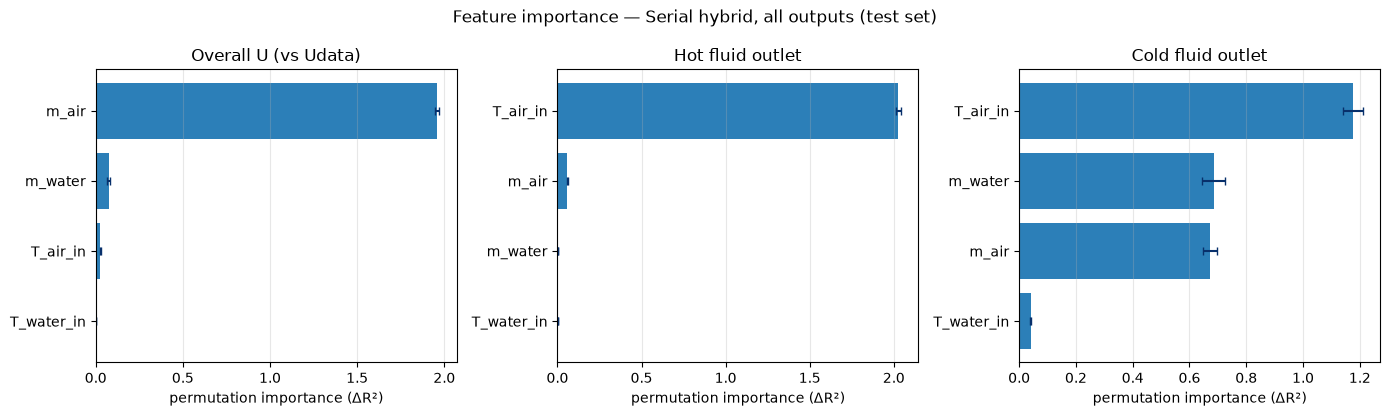

In [62]:
# FEATURE IMPORTANCE for all 3 outputs of the serial hybrid (test set)
# Permutation importance on the full pipeline: shuffle one input,
# re-run ML U -> physics E-NTU, and measure the drop in R² per output.
# Uses raw hybrid predictions (the Twout clip cell is not applied here).

fi_labels = np.array(feature_cols)   # m_air, m_water, T_air_in, T_water_in
output_names = ["Overall U (vs Udata)", "Hot fluid outlet", "Cold fluid outlet"]
N_REPEATS = 5      # shuffles per feature

X_fi = test_df[feature_cols].to_numpy(dtype=float)
Y_fi = test_df[["Udata", "T_air_out", "T_water_out"]].to_numpy(dtype=float)


def serial_hybrid_matrix(X):
    """Run the serial hybrid on every row of X -> array of [U, Taout, Twout]."""
    U = ml_U.predict(X)
    out = []
    for x, u in zip(X, U):
        r = serial_hybrid_predict(*x, U_pred=u)
        out.append([r["U_hybrid"], r["T_air_out_hybrid"], r["T_water_out_hybrid"]])
    return np.array(out)


def r2_per_output(Y_true, Y_pred):
    return np.array([r2_score(Y_true[:, j], Y_pred[:, j]) for j in range(Y_true.shape[1])])


rng = np.random.RandomState(42)
base_r2 = r2_per_output(Y_fi, serial_hybrid_matrix(X_fi))

n_feat = len(feature_cols)
imp_all = np.zeros((3, n_feat))   # mean R² drop  [output, feature]
err_all = np.zeros((3, n_feat))   # std of R² drop

for f in range(n_feat):
    drops = np.zeros((N_REPEATS, 3))
    for r in range(N_REPEATS):
        X_perm = X_fi.copy()
        X_perm[:, f] = rng.permutation(X_perm[:, f])
        drops[r] = base_r2 - r2_per_output(Y_fi, serial_hybrid_matrix(X_perm))
    imp_all[:, f] = drops.mean(axis=0)
    err_all[:, f] = drops.std(axis=0)
    print(f"Done: {feature_cols[f]}")

imp_df = pd.DataFrame(imp_all.T, index=fi_labels, columns=output_names)
print("\nPermutation importance (mean test R² drop):")
print(imp_df.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for j, ax in enumerate(axes):
    order = np.argsort(imp_all[j])
    ax.barh(
        fi_labels[order],
        imp_all[j, order],
        xerr=err_all[j, order],
        color="#2c7fb8",
        ecolor="#08306b",
        capsize=3,
    )
    ax.set_xlabel("permutation importance (ΔR²)")
    ax.set_title(output_names[j])
    ax.grid(True, axis="x", alpha=0.3)

plt.suptitle("Feature importance — Serial hybrid, all outputs (test set)")
plt.tight_layout()
plt.show()


## 7. Udata / dataset vs Serial model values (before clipping)

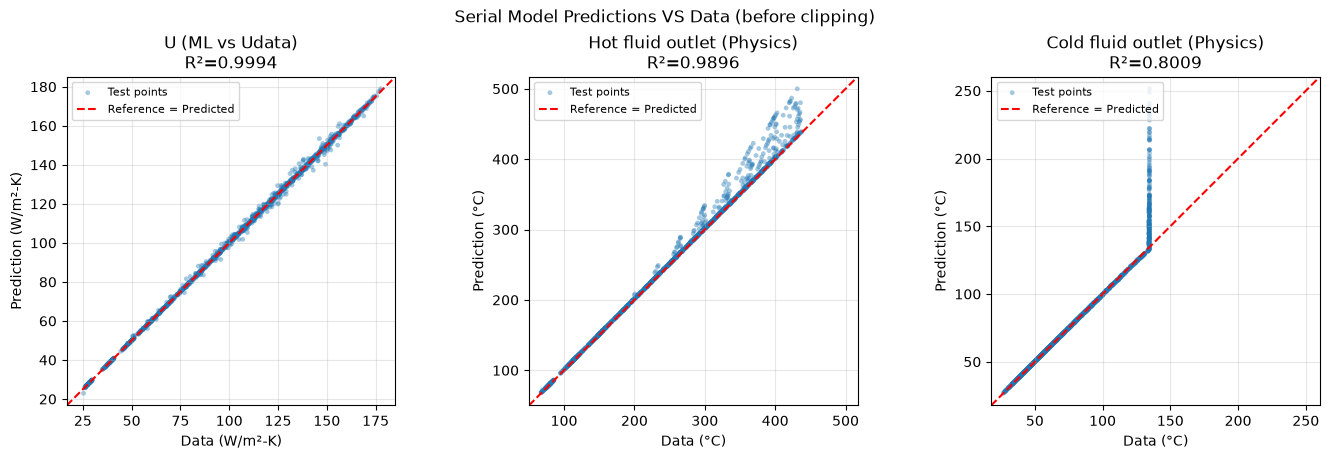

In [63]:
# Udata / dataset temps vs SERIAL HYBRID (test set) — BEFORE clipping
# Runs before the clip cell, so the cold fluid outlet shows the raw values.
# Points on the red dashed line (y = x) are perfect predictions.

pairs = [
    ("Udata", "U_hybrid", "U (ML vs Udata)", "W/m²-K"),
    ("T_air_out", "T_air_out_hybrid", "Hot fluid outlet (Physics)", "°C"),
    ("T_water_out", "T_water_out_hybrid", "Cold fluid outlet (Physics)", "°C"),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (actual_col, pred_col, name, unit) in zip(axes, pairs):
    y_true = test_df[actual_col].to_numpy(dtype=float)
    y_pred = test_df[pred_col].to_numpy(dtype=float)
    r2 = r2_score(y_true, y_pred)

    ax.scatter(y_true, y_pred, s=12, alpha=0.4, edgecolors="none", label="Test points")
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    pad = 0.04 * (hi - lo if hi > lo else 1.0)
    ax.plot(
        [lo - pad, hi + pad],
        [lo - pad, hi + pad],
        "r--",
        lw=1.5,
        label="Reference = Predicted",
    )
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel(f"Data ({unit})")
    ax.set_ylabel(f"Prediction ({unit})")
    ax.set_title(f"{name}\nR²={r2:.4f}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("Serial Model Predictions VS Data (before clipping)")
plt.tight_layout()
plt.show()


In [64]:
# =====================================================================
# CLIP WATER OUTLET AT SATURATION TEMPERATURE  (separate post-processing)
# =====================================================================
# In data.csv the water outlet never goes above ~134.6 °C: at the water-side
# pressure (~3 bar) the water starts boiling, and extra heat goes into
# evaporation instead of raising the temperature.
# The physics E-NTU treats water as liquid only, so it can predict values
# above this. Here we simply cap the prediction at T_SAT_WATER.
# The serial hybrid model itself is NOT changed — delete/skip this cell to undo.

T_SAT_WATER = 134.6   # °C, max water outlet seen in data.csv

# Keep the original (unclipped) prediction for reference
test_df["T_water_out_hybrid_raw"] = test_df["T_water_out_hybrid"]

# Cap the prediction at the saturation temperature
test_df["T_water_out_hybrid"] = test_df["T_water_out_hybrid_raw"].clip(upper=T_SAT_WATER)

n_clipped = int((test_df["T_water_out_hybrid_raw"] > T_SAT_WATER).sum())
print(f"Clipped {n_clipped} of {len(test_df)} test rows at T_sat = {T_SAT_WATER} °C")
# ====================== END OF CLIP SECTION ==========================


Clipped 164 of 1506 test rows at T_sat = 134.6 °C


## 8. Udata / dataset vs Serial model values (after clipping)


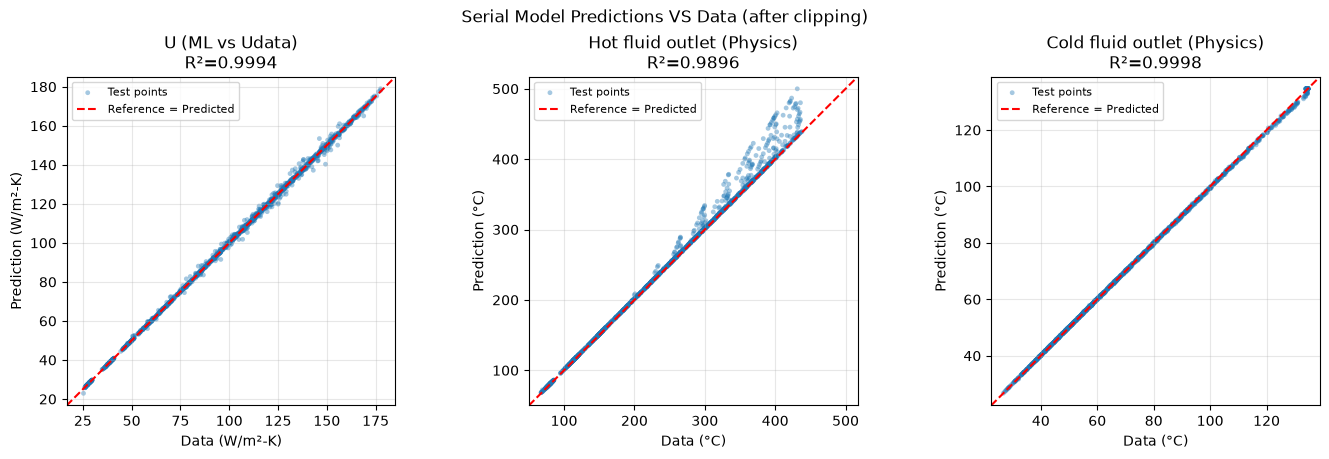

In [65]:
# Udata / dataset temps vs SERIAL HYBRID (test set)
# Points on the red dashed line (y = x) are perfect predictions.

pairs = [
    ("Udata", "U_hybrid", "U (ML vs Udata)", "W/m²-K"),
    ("T_air_out", "T_air_out_hybrid", "Hot fluid outlet (Physics)", "°C"),
    ("T_water_out", "T_water_out_hybrid", "Cold fluid outlet (Physics)", "°C"),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (actual_col, pred_col, name, unit) in zip(axes, pairs):
    y_true = test_df[actual_col].to_numpy(dtype=float)
    y_pred = test_df[pred_col].to_numpy(dtype=float)
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))

    ax.scatter(y_true, y_pred, s=12, alpha=0.4, edgecolors="none", label="Test points")
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    pad = 0.04 * (hi - lo if hi > lo else 1.0)
    ax.plot(
        [lo - pad, hi + pad],
        [lo - pad, hi + pad],
        "r--",
        lw=1.5,
        label="Reference = Predicted",
    )
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel(f"Data ({unit})")
    ax.set_ylabel(f"Prediction ({unit})")
    ax.set_title(f"{name}\nR²={r2:.4f}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("Serial Model Predictions VS Data (after clipping)")
plt.tight_layout()
plt.show()


## 9. Digital Twin

Enter the 4 inputs -> get serial hybrid `U` (ML on Udata), `Taout`, `Twout` (physics E-NTU).


In [66]:
# DIGITAL TWIN - serial hybrid
# User gives mass flows (kg/h) and inlet temperatures (C).
# Returns U (ML trained on Udata), Taout/Twout (physics E-NTU with TEMA area).


def digital_twin(m_air_kgh, m_water_kgh, T_air_in, T_water_in,
                 P_air_in_atm=P_AIR_IN / ATM, P_water_in_atm=P_WATER_IN / ATM, verbose=True):
    """
    Serial hybrid digital twin for the shell-and-tube heat exchanger.

    Inputs (same units as data.csv):
      - m_air_kgh, m_water_kgh       : mass flows in kg/h
      - T_air_in, T_water_in         : inlet temperatures in °C
      - P_air_in_atm, P_water_in_atm : inlet pressures in atm (absolute)
    """
    m_air = m_air_kgh / 3600.0
    m_water = m_water_kgh / 3600.0

    out = serial_hybrid_predict(
        m_air, m_water, T_air_in, T_water_in,
        P_air_in=P_air_in_atm * ATM, P_water_in=P_water_in_atm * ATM,
    )

    if verbose:
        print("==========================================")
        print("  DIGITAL TWIN — SERIAL HYBRID")
        print(f"  U model: {best['name']}")
        print("  ML(U from Udata) -> Physics E-NTU (Taout, Twout)")
        print("==========================================")
        print("\nINPUTS")
        print(f"  Air mass flow      : {m_air_kgh:.2f} kg/h  ({m_air:.4f} kg/s)")
        print(f"  Water mass flow    : {m_water_kgh:.2f} kg/h  ({m_water:.4f} kg/s)")
        print(f"  Air inlet temp     : {T_air_in:.2f} °C")
        print(f"  Water inlet temp   : {T_water_in:.2f} °C")
        print(f"  Air inlet press.   : {P_air_in_atm:.2f} atm  ({P_air_in_atm * ATM / 1000.0:.2f} kPa)")
        print(f"  Water inlet press. : {P_water_in_atm:.2f} atm  ({P_water_in_atm * ATM / 1000.0:.2f} kPa)")
        print("\nOUTPUTS")
        print(f"  Overall U (ML / Udata)     : {out['U_hybrid']:.2f} W/m²-K")
        print(f"  Air outlet temp    : {out['T_air_out_hybrid']:.2f} °C")
        print(f"  Water outlet temp  : {out['T_water_out_hybrid']:.2f} °C")
        print(f"  Duty (physics)     : {out['Q_kW']:.2f} kW")

    return out


# Example (Case 1 style)
_ = digital_twin(10001, 10001, 100, 25)


  DIGITAL TWIN — SERIAL HYBRID
  U model: 2) Random Forest
  ML(U from Udata) -> Physics E-NTU (Taout, Twout)

INPUTS
  Air mass flow      : 10001.00 kg/h  (2.7781 kg/s)
  Water mass flow    : 10001.00 kg/h  (2.7781 kg/s)
  Air inlet temp     : 100.00 °C
  Water inlet temp   : 25.00 °C
  Air inlet press.   : 1.50 atm  (151.99 kPa)
  Water inlet press. : 2.00 atm  (202.65 kPa)

OUTPUTS
  Overall U (ML / Udata)     : 22.92 W/m²-K
  Air outlet temp    : 72.14 °C
  Water outlet temp  : 31.73 °C
  Duty (physics)     : 78.11 kW


In [67]:
# --- USER INPUT: change values and re-run ---
user_m_air_kgh = 14401      # kg/h
user_m_water_kgh = 13001    # kg/h
user_T_air_in = 312         # °C
user_T_water_in = 35        # °C

twin = digital_twin(
    user_m_air_kgh,
    user_m_water_kgh,
    user_T_air_in,
    user_T_water_in,
)


  DIGITAL TWIN — SERIAL HYBRID
  U model: 2) Random Forest
  ML(U from Udata) -> Physics E-NTU (Taout, Twout)

INPUTS
  Air mass flow      : 14401.00 kg/h  (4.0003 kg/s)
  Water mass flow    : 13001.00 kg/h  (3.6114 kg/s)
  Air inlet temp     : 312.00 °C
  Water inlet temp   : 35.00 °C
  Air inlet press.   : 1.50 atm  (151.99 kPa)
  Water inlet press. : 2.00 atm  (202.65 kPa)

OUTPUTS
  Overall U (ML / Udata)     : 38.01 W/m²-K
  Air outlet temp    : 199.44 °C
  Water outlet temp  : 65.44 °C
  Duty (physics)     : 458.28 kW
